# Caracterización exploratoria de las representaciones contextuales

Complemento P22 para los **anexos**. Examina la variación entre ocurrencias y la información que se pierde al resumir una palabra mediante un promedio. Corresponde al mismo banco congelado P20 del estudio controlado: 640 palabras, 64.000 ocurrencias, 1.286 prototipos y 376 palabras COMMON.

Esta caracterización es diferente del experimento contextual preliminar excluido. No repite recuperación, clasificación ni selección de K. A=promedio por palabra; P=prototipos congelados; O=ocurrencias. Los tamaños diagnósticos k=1,2,4,8 pertenecen a pruebas de reconstrucción y no son el K=80 de las listas de vecinos.

La ejecución lee resultados guardados y regenera figuras. No necesita las matrices originales ni el corpus completo.

In [8]:
from pathlib import Path
import sys
from IPython.display import display, Markdown
HERE = Path.cwd().resolve()
BASE = next((p for p in (HERE, HERE / "EstudioContextual/CaracterizacionExploratoria",
                        HERE / "CaracterizacionExploratoria")
             if (p / "CodigoComun/exploratorio_guardado.py").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Abre el notebook desde ProyectoTesis, EstudioContextual o CaracterizacionExploratoria.")
sys.path.insert(0, str(BASE / "CodigoComun"))
from exploratorio_guardado import SavedExploration
ESTUDIO = SavedExploration(BASE / "ResultadosGuardados/P22_resultados.zip")
VERIFICACION = ESTUDIO.verify()
display(VERIFICACION)

{'status': 'VERIFIED',
 'contract_id': '2639d8e76465de84146d39074a41604cf15d126de25999bb86f7d65162c4fcd8',
 'bank_id': '68682213c8913476a11a1ef997136dbcb80ec50eeedb4f466cb8dd8deae8b981',
 'word_receipts': 640,
 'words': 640,
 'occurrences': 64000,
 'prototypes': 1286,
 'common_words': 376,
 'probe_status': {'OK': 37768, 'NOT_EVALUABLE': 632},
 'text_status': {'OK': 625, 'NOT_EVALUABLE': 15},
 'checkpoint_tables_reconciled': True,
 'summary_point_estimates_reconciled': True,
 'raw_embeddings_rechecked': False,
 'bootstrap_intervals_recomputed': False,
 'new_experiments': 0}

## 1. Alcance y condiciones de análisis

El análisis se limita a la cohorte controlada; no describe todo el vocabulario contextual original. Los intervalos guardados se obtuvieron mediante remuestreo de palabras dentro de categorías fijas y expresan sensibilidad condicional. Las palabras pueden compartir documentos de origen. Las cinco particiones repetidas no son cinco corpus independientes.

In [9]:
display(ESTUDIO.plan["scientific_config"])
display(ESTUDIO.json("DEPENDENCE_AUDIT.json"))
display(ESTUDIO.json("TEXT_STATUS.json"))

{'bank': 'C:\\Users\\jisaa\\E6R\\p20_68682213c891',
 'source_parquet': None,
 'use_text': True,
 'split_seeds': [0, 1, 2, 3, 4],
 'probe_k': [1, 2, 4, 8],
 'training_fractions': [0.25, 0.5, 1.0],
 'test_group_fraction': 0.2,
 'kmeans_n_init': 5,
 'kmeans_max_iter': 100,
 'control_repetitions': 20,
 'text_permutations': 199,
 'bootstrap_repetitions': 2000,
 'nearest_neighbors': 10,
 'min_train_occurrences': 16,
 'min_test_occurrences': 10,
 'min_source_groups': 10}

{'source_records': 46556,
 'shared_by_multiple_words': 5441,
 'maximum_words_per_source_record': 26,
 'full_document_independence': 'NOT_ESTABLISHED',
 'bootstrap_limitation': 'Words may share source records; intervals are conditional sensitivity summaries.'}

{'status': 'AVAILABLE',
 'path': 'C:\\Users\\jisaa\\Workspace\\Tesis\\Exp2\\Results\\contextual_dataset\\contextual_occurrences_definitive.parquet',
 'column': 'context_window',
 'selected_content_sha256': '12c115c7a5cd2fbdca6ce83a59e24b4dbe935c50542224f5609703763637cecf',
 'source_size': 41281045347,
 'full_source_rehashed': False,
 'canonical_identities_verified': True,
 'semantic_validation': False}

## 2. Variación contextual y agregación

Se recuperan dispersión direccional, similitud intrapalabra frente a otras palabras, descomposición de varianza y cambios de vecindario. La retención de varianza de los prototipos originales es descriptiva; no demuestra generalización ni validez de sentidos lingüísticos.

In [10]:
display(ESTUDIO.tables["geometry_summary"])
display(ESTUDIO.tables["category_geometry"])

,scope,metric,status,estimate,bootstrap_low,bootstrap_high,n_words,n_categories,interval
0,COHORT,total_variance,OK,95.329225,93.214475,97.348652,640,8,95% within-category word-bootstrap; conditiona...
1,COHORT,frozen_P_retained_fraction,OK,0.134362,0.127394,0.141577,640,8,95% within-category word-bootstrap; conditiona...
2,COHORT,random_partition_expected_fraction,OK,0.010196,0.009612,0.010795,640,8,95% within-category word-bootstrap; conditiona...
3,COHORT,raw_self_cosine,OK,0.676674,0.671791,0.681807,640,8,95% within-category word-bootstrap; conditiona...
4,COHORT,other_word_cosine,OK,0.351145,0.349039,0.353209,640,8,95% within-category word-bootstrap; conditiona...
5,COHORT,adjusted_self_cosine,OK,0.325529,0.321376,0.329666,640,8,95% within-category word-bootstrap; conditiona...
6,COHORT,directional_variance,OK,0.320093,0.315276,0.325010,640,8,95% within-category word-bootstrap; conditiona...
7,COHORT,norm_shrinkage,OK,0.823223,0.820062,0.826303,640,8,95% within-category word-bootstrap; conditiona...
8,COHORT,centered_PC1_fraction,OK,0.167566,0.163900,0.171465,640,8,95% within-category word-bootstrap; conditiona...
9,COHORT,centered_effective_rank,OK,39.510719,39.060509,39.958332,640,8,95% within-category word-bootstrap; conditiona...


,category,n_words,mean_retained,mean_directional_variance,mean_neighbor_change,minimum_source_groups
0,apple,80,0.154106,0.390942,0.555500,48
1,bicycle,80,0.128510,0.310692,0.318875,58
2,bread,80,0.089139,0.313172,0.344500,55
3,canoe,80,0.123499,0.299303,0.409500,47
4,chair,80,0.122693,0.368774,0.486875,73
5,jellyfish,80,0.164456,0.287948,0.503750,21
6,screwdriver,80,0.126034,0.300576,0.489875,58
7,skunk,80,0.166462,0.289336,0.471000,34


## 3. Reconstrucción fuera de muestra y controles

Los centroides diagnósticos se ajustaron exclusivamente con los grupos de entrenamiento. Se contrastan con promedios, particiones aleatorias del mismo tamaño y referencias gaussianas. Son pruebas de representación, no nuevas variantes de recuperación ni el procedimiento original de inducción de pseudosentidos. Se muestran también las condiciones desfavorables y no evaluables.

In [11]:
display(ESTUDIO.tables["heldout_summary"].query("scope == 'COHORT' and training_fraction == 1.0"))
display(ESTUDIO.tables["occurrence_reference_summary"])
display(ESTUDIO.tables["probe_coverage"])

,scope,training_fraction,k,metric,status,estimate,bootstrap_low,bootstrap_high,n_words,n_categories,interval
112,COHORT,1.0,1,relative_gain,OK,-1.006140e-18,-2.568258e-18,6.245005e-19,640,8,95% within-category word-bootstrap; conditiona...
113,COHORT,1.0,1,gain_minus_random,NOT_EVALUABLE_MISSING_CATEGORY,NaN,NaN,NaN,0,0,NaN
114,COHORT,1.0,1,gain_minus_gaussian,NOT_EVALUABLE_MISSING_CATEGORY,NaN,NaN,NaN,0,0,NaN
115,COHORT,1.0,1,stability_ARI,NOT_EVALUABLE_MISSING_CATEGORY,NaN,NaN,NaN,0,0,NaN
116,COHORT,1.0,1,gaussian_MC_se,NOT_EVALUABLE_MISSING_CATEGORY,NaN,NaN,NaN,0,0,NaN
117,COHORT,1.0,1,angular_test_error,OK,1.821123e-01,1.787608e-01,1.853844e-01,640,8,95% within-category word-bootstrap; conditiona...
118,COHORT,1.0,1,test_outside_train_span_fraction,OK,3.663746e-01,3.631008e-01,3.695676e-01,640,8,95% within-category word-bootstrap; conditiona...
126,COHORT,1.0,2,relative_gain,OK,1.050255e-01,1.009223e-01,1.089990e-01,640,8,95% within-category word-bootstrap; conditiona...
127,COHORT,1.0,2,gain_minus_random,OK,8.244718e-02,7.891774e-02,8.616268e-02,640,8,95% within-category word-bootstrap; conditiona...
128,COHORT,1.0,2,gain_minus_gaussian,OK,1.397486e-02,1.156031e-02,1.642715e-02,640,8,95% within-category word-bootstrap; conditiona...


,scope,training_fraction,mean_codebook_size,metric,status,estimate,bootstrap_low,bootstrap_high,n_words,n_categories,interval
0,COHORT,0.25,20.763594,O_train_gain,OK,-0.089441,-0.096268,-0.081783,640,8,95% within-category word-bootstrap; conditiona...
1,COMMON,0.25,20.910872,O_train_gain,OK,-0.085767,-0.095493,-0.075617,376,8,95% within-category word-bootstrap; conditiona...
2,COHORT,0.50,39.927813,O_train_gain,OK,-0.012399,-0.019682,-0.004497,640,8,95% within-category word-bootstrap; conditiona...
3,COMMON,0.50,39.887589,O_train_gain,OK,-0.009244,-0.019043,0.000921,376,8,95% within-category word-bootstrap; conditiona...
4,COHORT,1.00,79.516250,O_train_gain,OK,0.071660,0.064219,0.079043,640,8,95% within-category word-bootstrap; conditiona...
5,COMMON,1.00,79.481716,O_train_gain,OK,0.075284,0.065247,0.085663,376,8,95% within-category word-bootstrap; conditiona...


,category,training_fraction,k,status,word_split_cells
0,apple,0.25,1,NOT_EVALUABLE,6
1,apple,0.25,1,OK,394
2,apple,0.25,2,NOT_EVALUABLE,6
3,apple,0.25,2,OK,394
4,apple,0.25,4,NOT_EVALUABLE,6
...,...,...,...,...,...
135,skunk,1.00,2,OK,399
136,skunk,1.00,4,NOT_EVALUABLE,1
137,skunk,1.00,4,OK,399
138,skunk,1.00,8,NOT_EVALUABLE,1


## 4. Sensibilidad y asociación con el texto

Las omisiones de categoría de P22 son descriptivas y no son los reajustes LOCO de T1–T3. La asociación con contextos textuales se evalúa en 625 palabras; se conservan los 15 casos no evaluables. La asociación léxica no constituye una anotación independiente de sentidos.

In [12]:
display(ESTUDIO.tables["category_omissions"])
display(ESTUDIO.tables["text_summary"])
display(ESTUDIO.csv("text_alignment.csv").status.value_counts())

,k,omitted_category,metric,estimate,scope,interpretation
0,1,apple,relative_gain,-9.119689e-19,COHORT,Descriptive omission; no refitting or T1/T2/T3
1,1,apple,gain_minus_random,NaN,COHORT,Descriptive omission; no refitting or T1/T2/T3
2,1,apple,gain_minus_gaussian,NaN,COHORT,Descriptive omission; no refitting or T1/T2/T3
3,1,apple,stability_ARI,NaN,COHORT,Descriptive omission; no refitting or T1/T2/T3
4,1,apple,gaussian_MC_se,NaN,COHORT,Descriptive omission; no refitting or T1/T2/T3
...,...,...,...,...,...,...
219,8,skunk,gain_minus_gaussian,5.493780e-02,COHORT,Descriptive omission; no refitting or T1/T2/T3
220,8,skunk,stability_ARI,3.493063e-01,COHORT,Descriptive omission; no refitting or T1/T2/T3
221,8,skunk,gaussian_MC_se,8.302985e-03,COHORT,Descriptive omission; no refitting or T1/T2/T3
222,8,skunk,angular_test_error,1.434811e-01,COHORT,Descriptive omission; no refitting or T1/T2/T3


,metric,status,estimate,bootstrap_low,bootstrap_high,n_words,n_categories,interval
0,spearman,OK,0.302616,0.294049,0.311514,625,8,95% within-category word-bootstrap; conditiona...
1,rho_minus_null,OK,0.302623,0.293740,0.311504,625,8,95% within-category word-bootstrap; conditiona...


status
OK               625
NOT_EVALUABLE     15
Name: count, dtype: int64

## 5. Figuras para anexos

Se regeneran seis figuras en inglés, con paneles identificados, desde las tablas guardadas. Se exportan PNG, PDF y SVG. No son heatmaps β×similitud, por lo que no se les aplica el recorte beta ni el formato cuadrado de esos heatmaps. Los textos y la presentación se pueden modificar en CodigoComun/figuras_exploratorio.py sin alterar la fuente científica.

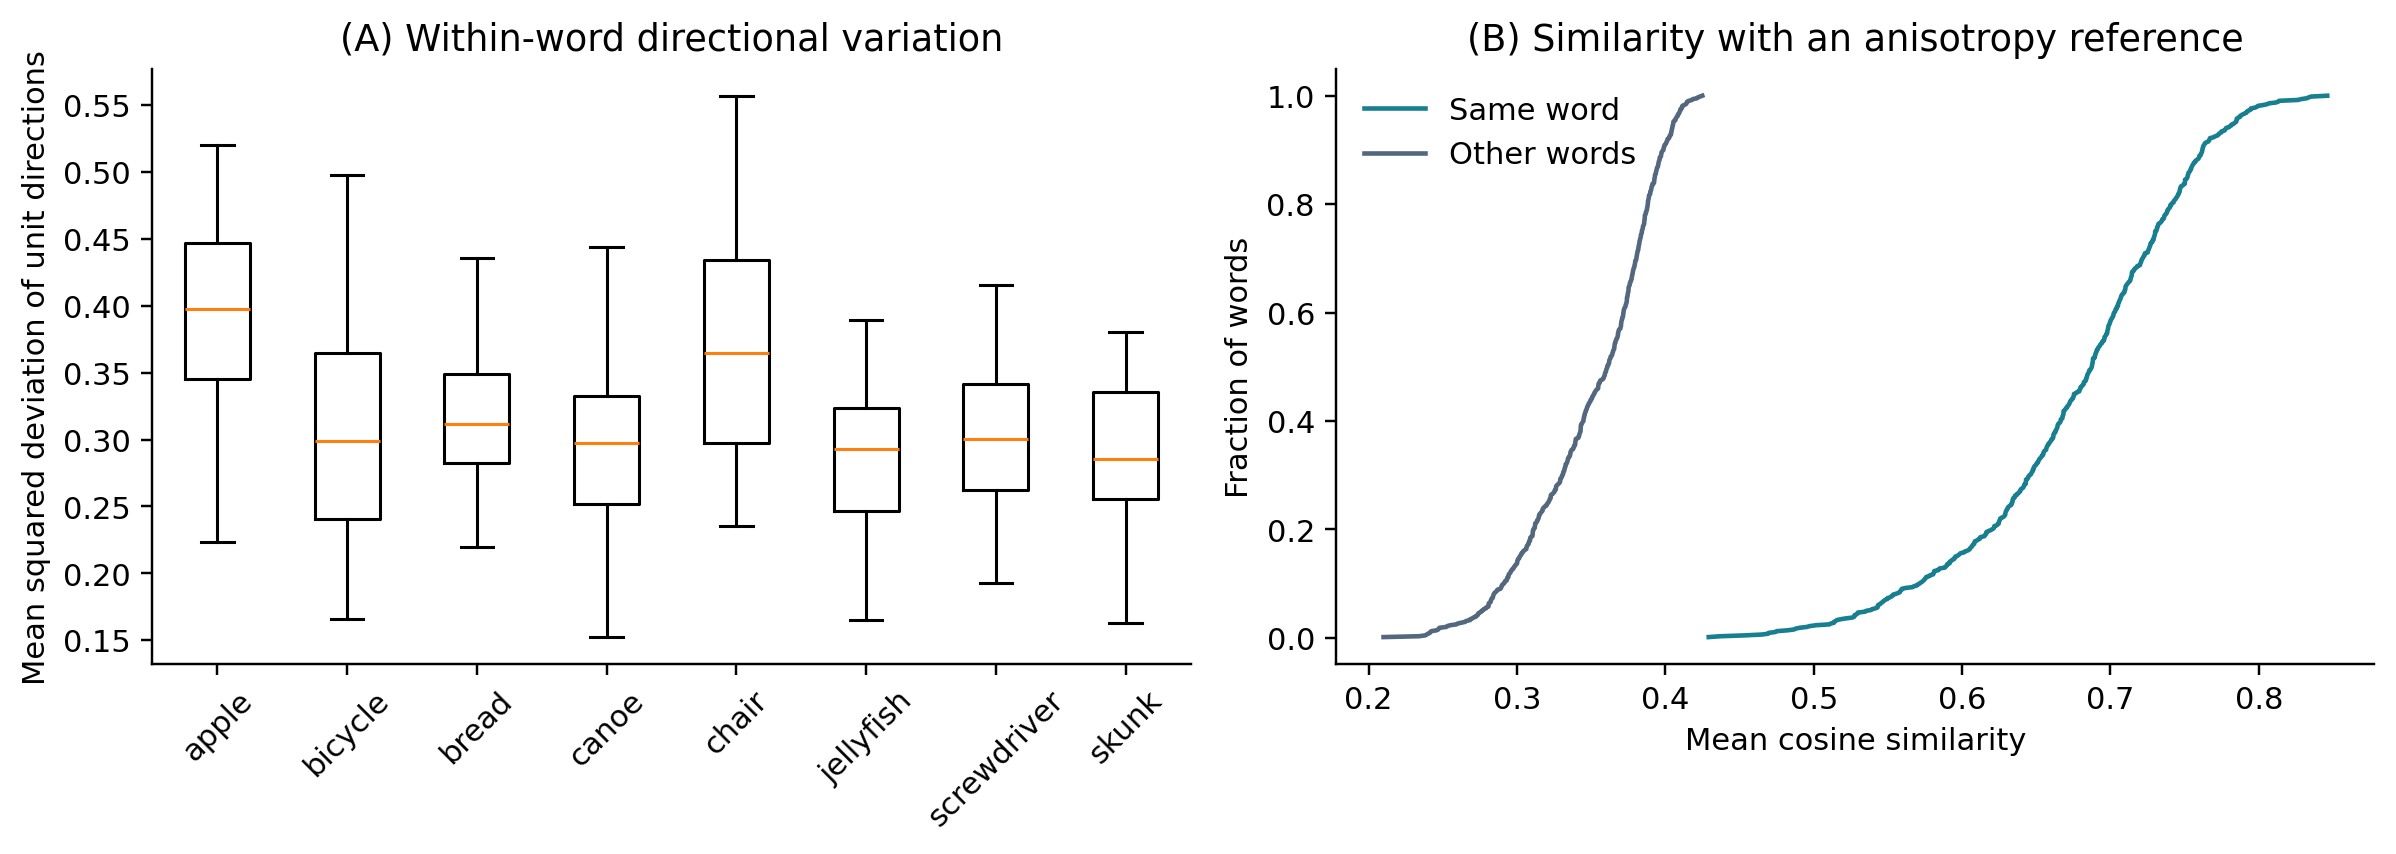

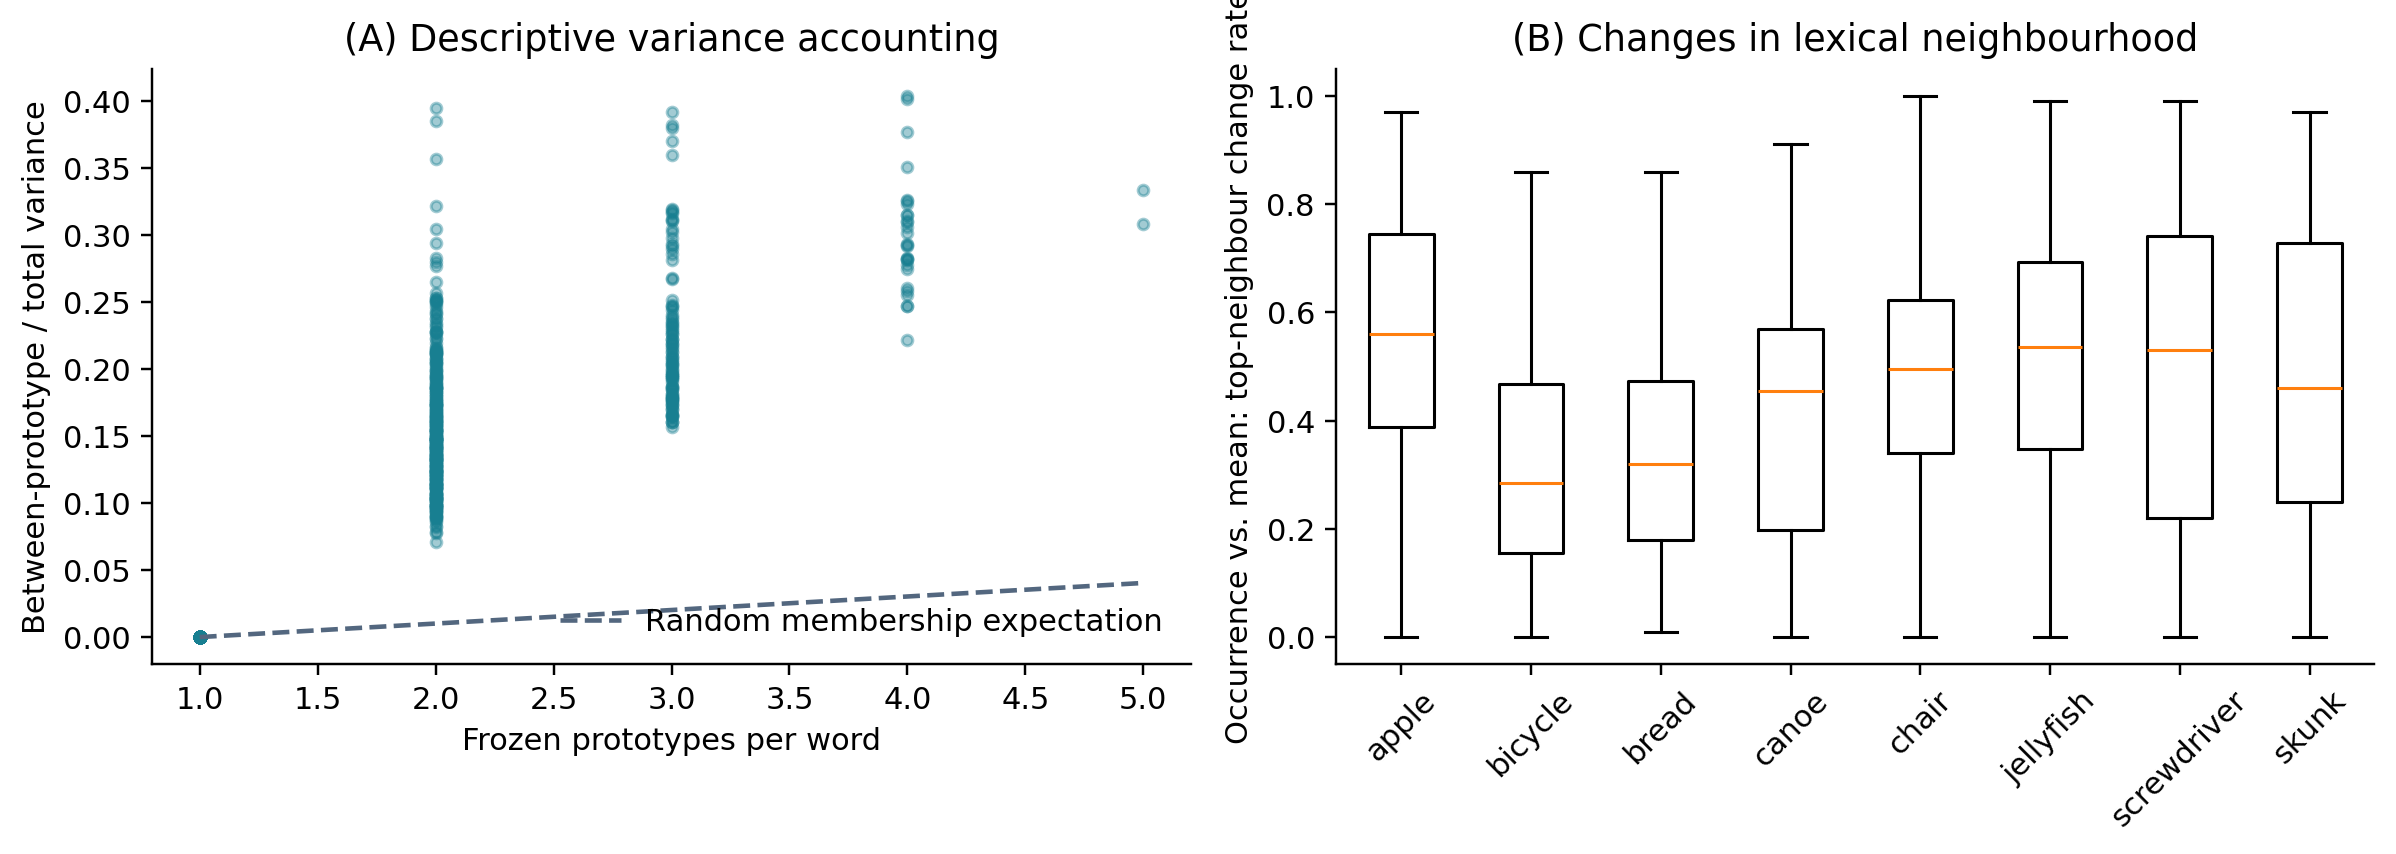

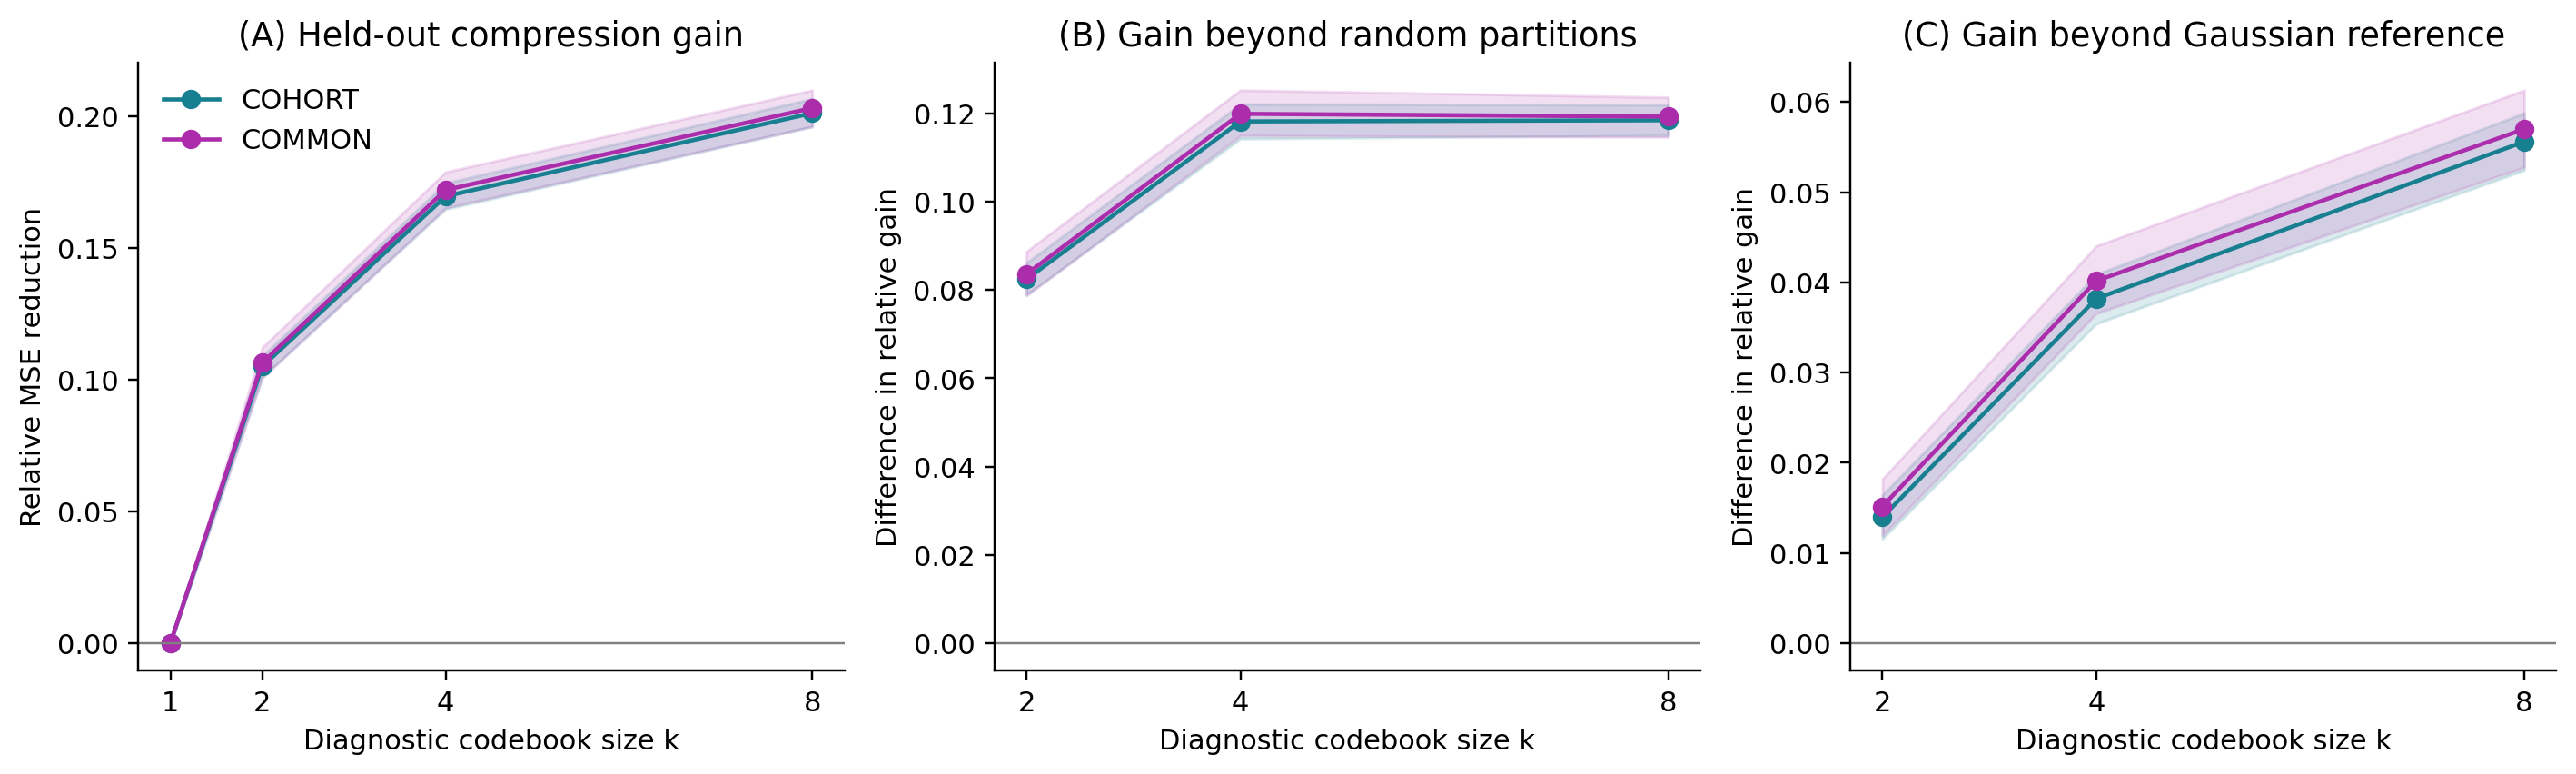

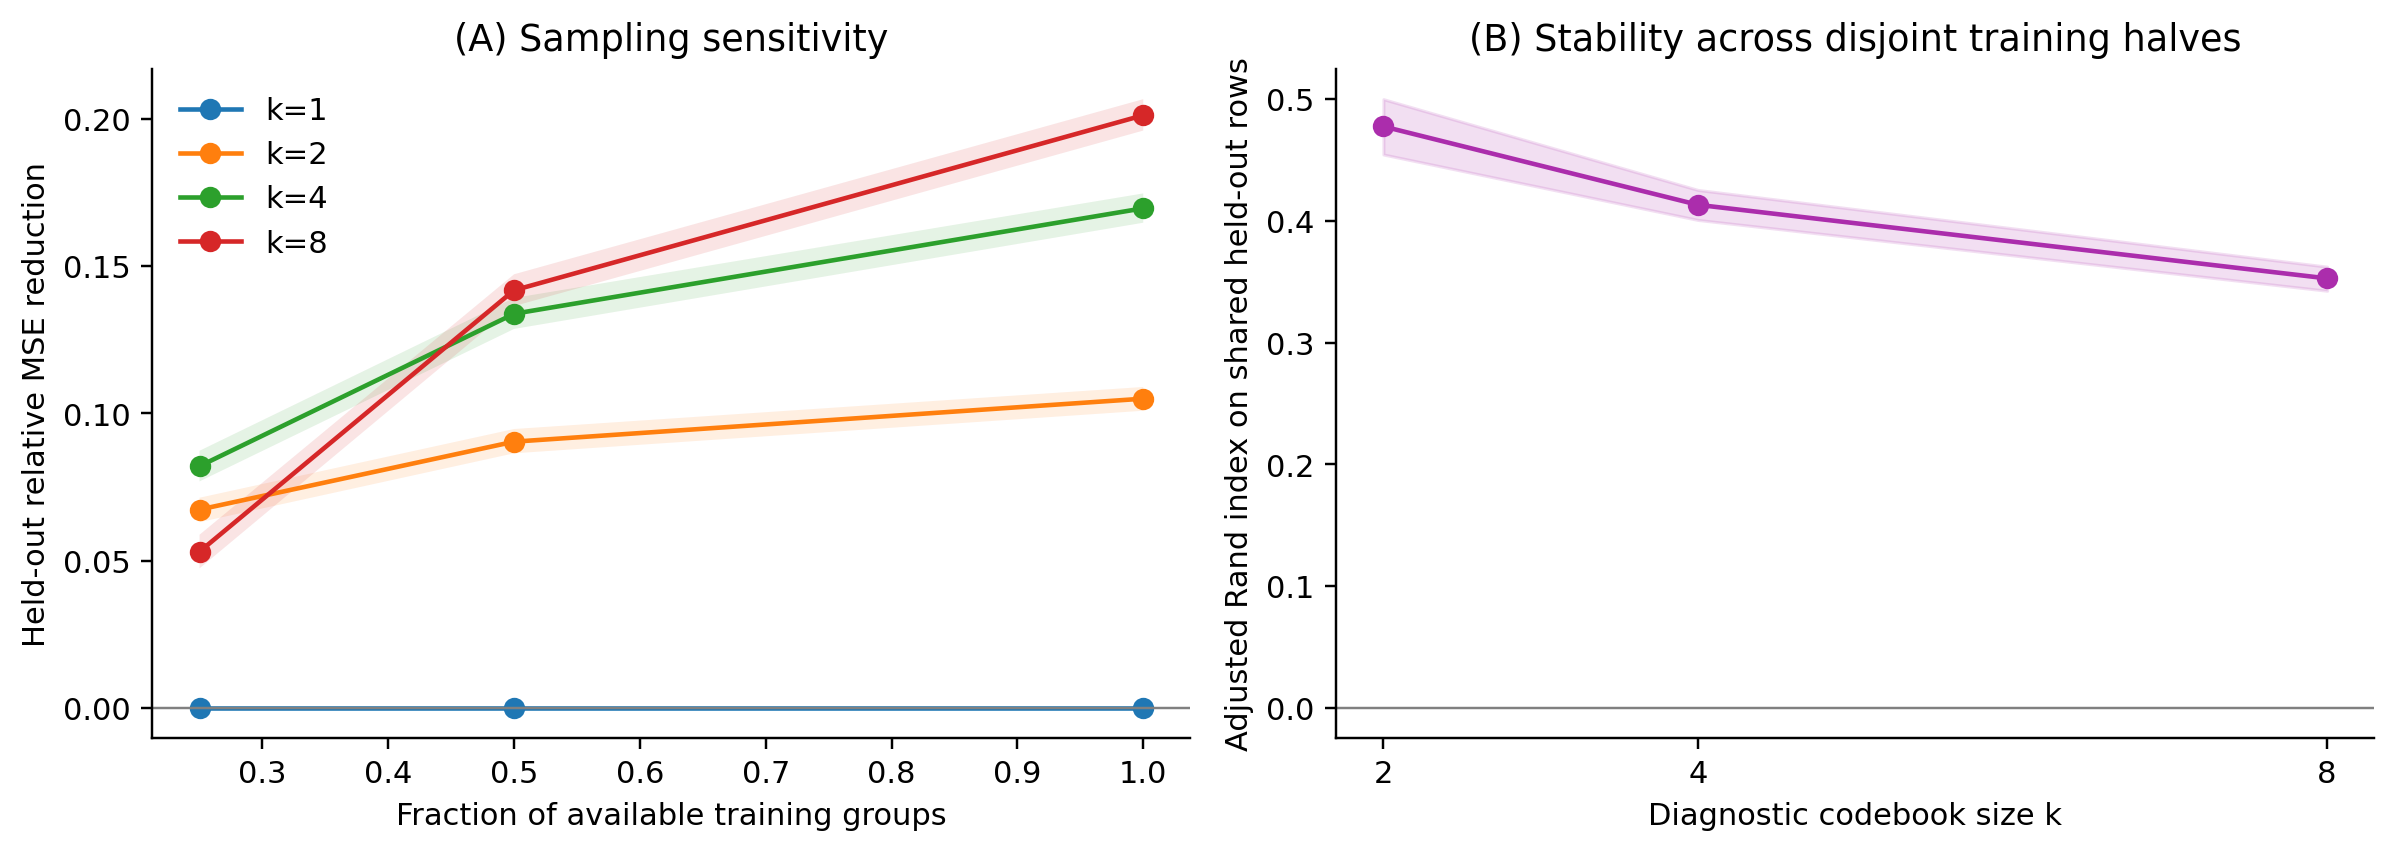

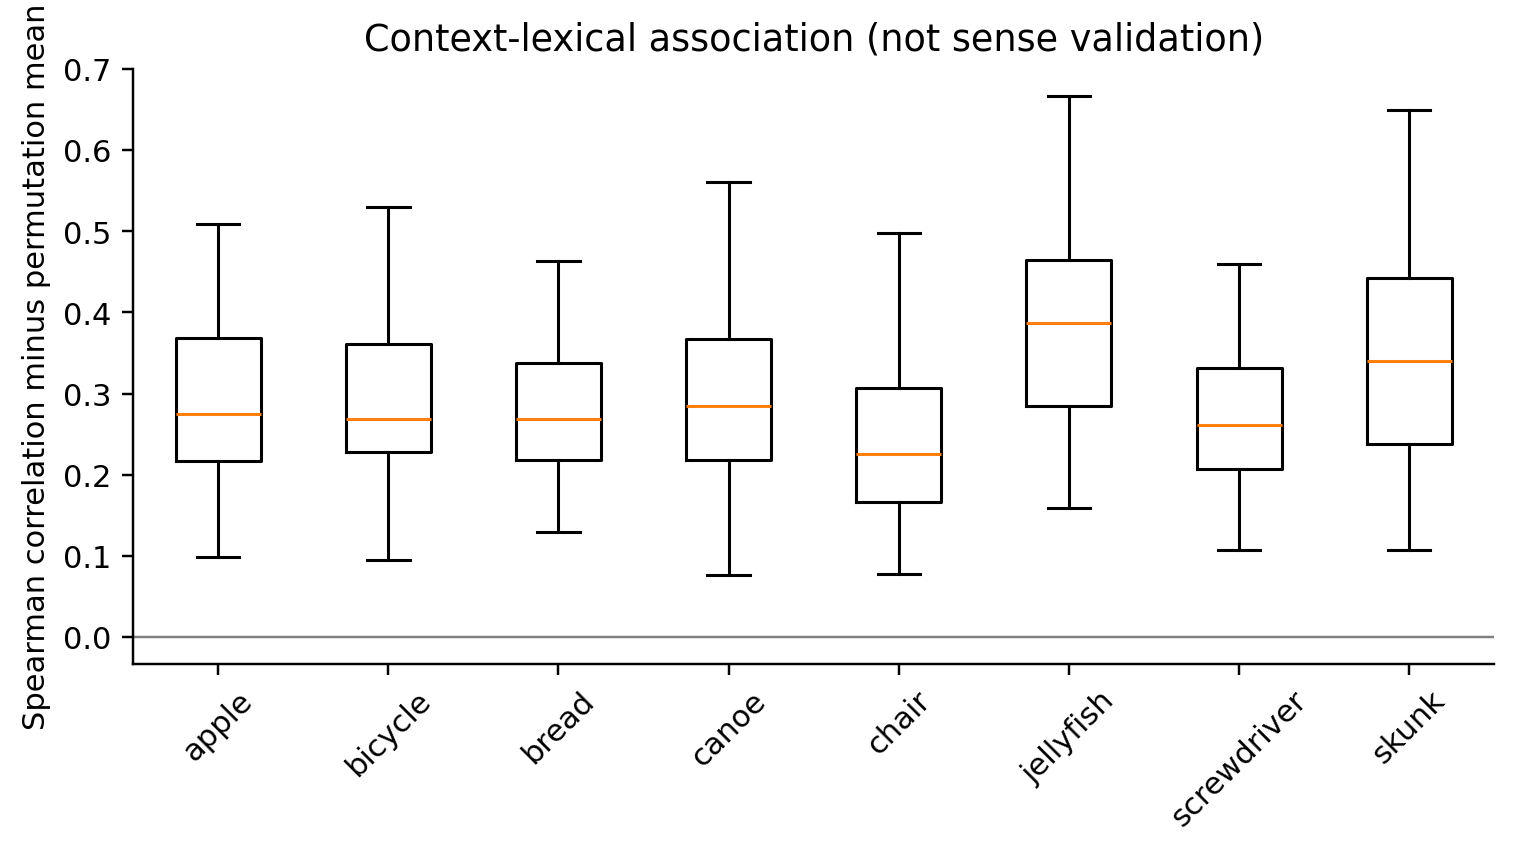

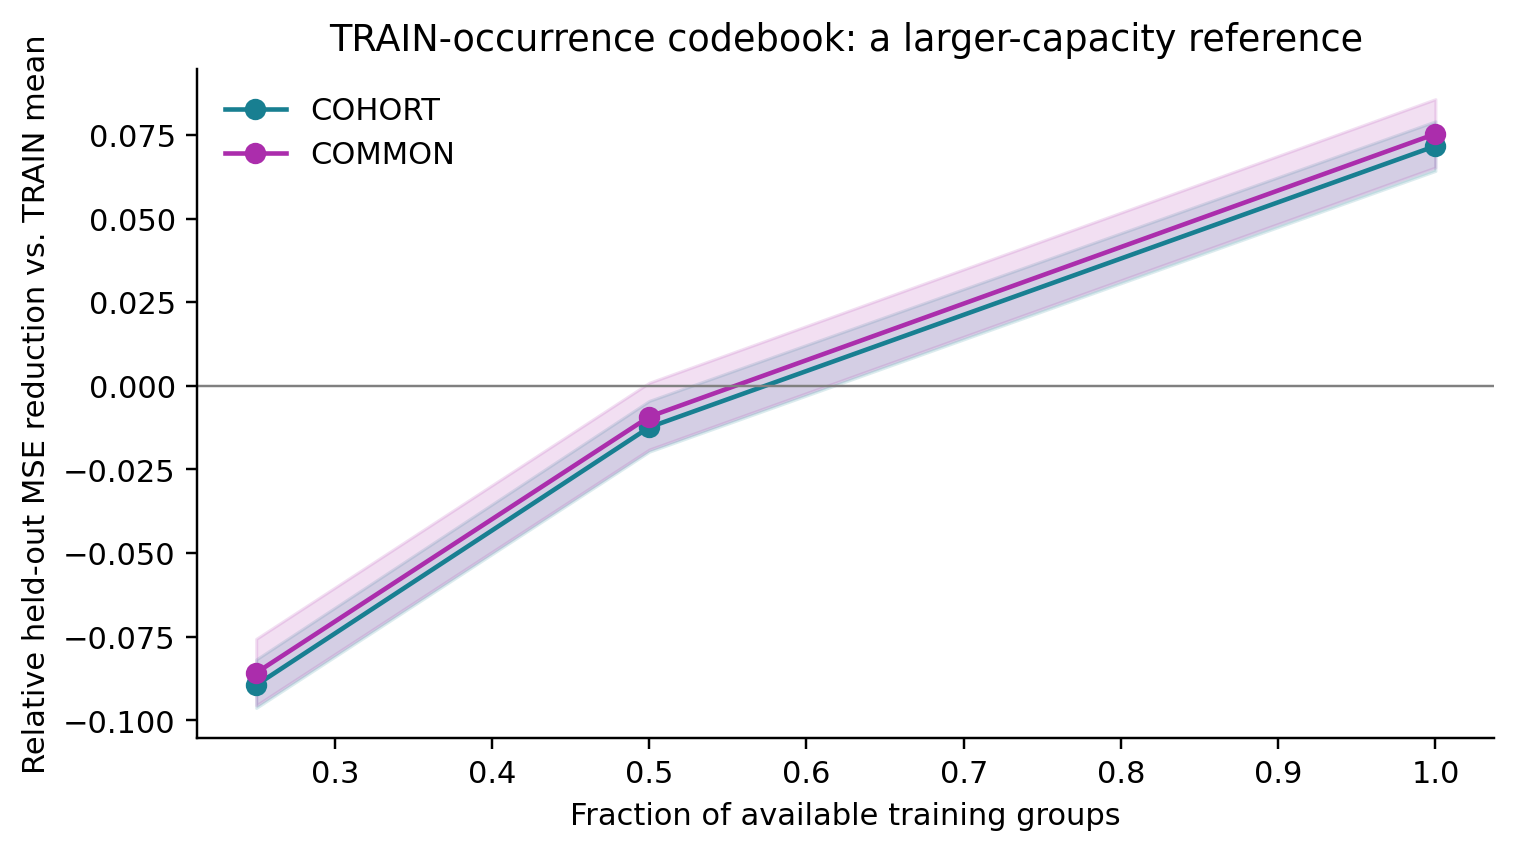

Figuras guardadas en: C:\Users\jisaa\Documents\ProyectoTesis\EstudioContextual\CaracterizacionExploratoria\SalidasRevision\figures


In [13]:
SALIDAS = BASE / "SalidasRevision"
DPI = 220
FORMATOS = ("png", "pdf", "svg")
FIGURAS = ESTUDIO.plot(SALIDAS, dpi=DPI, formats=FORMATOS, show=True)
print("Figuras guardadas en:", SALIDAS / "figures")

## 6. Informe original y trazabilidad

Se conserva el informe de la corrida. Sus sugerencias originales de ubicación en el manuscrito se subordinan a la decisión actual: esta caracterización se presenta en anexos y se referencia desde el texto donde corresponda. No sustituye al estudio controlado ni modifica automáticamente el resumen aprobado.

In [14]:
display(Markdown(ESTUDIO.data["REPORT.md"].decode("utf-8")))

# P22 exploratory contextual-representation report

Status: computational analysis complete for 640 words. Contract: `2639d8e76465de84146d39074a41604cf15d126de25999bb86f7d65162c4fcd8`.

This study characterizes the frozen P20/P21 cohort. It does not rerun memory retrieval,
fit the thesis classifier, select K, or use T1, T2, or T3. All comparisons are conditional
on this corpus, representation extraction, and lexical inventory.

## What to inspect

1. `tables/geometry_summary.csv`: contextual dispersion, anisotropy reference,
   prototype variance accounting, and changes in nearest lexical neighbours.
2. `tables/heldout_summary.csv`: every fixed probe-k and training fraction. Read
   relative compression gains jointly with random-partition and Gaussian controls.
3. `tables/probe_coverage.csv`: non-evaluable cells and their denominators.
4. `tables/category_omissions.csv`: category dependence without refitting.
5. `tables/text_summary.csv`: lexical-context association, when source texts exist.
6. `tables/occurrence_reference_summary.csv`: all TRAIN occurrences as a codebook,
   compared with the TRAIN mean; codebook capacities differ and are reported.

## Interpretation limits

The A=0 and O=1 endpoints for retained within-word variance follow by construction.
Frozen P is fitted on the same occurrences; its retained fraction is descriptive.
Held-out probes therefore refit all centroids on TRAIN records only. These diagnostic
K-means centroids are not the historical P induction algorithm or new retrieval arms.
Their test queries retain their full occurrence vectors to choose a nearest centroid;
this is a quantization test, not a deployment test with only a word identifier.
Within-word source-group hold-outs differ from the main word-disjoint retrieval
partitions and do not constitute additional retrieval trials.

A multi-centroid gain alone cannot establish distinct senses. A continuous unimodal
cloud can also benefit from quantization. The Gaussian control uses the full empirical
TRAIN covariance in its train span, with no shrinkage or added residual variance;
its contrast is sensitive to that finite-sample reference and is not a test of a
universal unimodality null. Inspect the test variance outside the train span as well.

Bootstrap intervals resample words within each of the fixed categories after averaging
repeated splits. They do not treat occurrence pairs, null draws, or repeated splits as
independent observations. They are conditional word-resampling summaries, not evidence
of replication in a new corpus. 5441 source records
are shared by multiple cohort words; document independence is not established.

Text status counts: {"OK": 625, "NOT_EVALUABLE": 15}.
Text association uses masked-target TF-IDF and record/duplicate groups. It measures
lexical context association, not independent human sense annotation. No automatic
semantic interpretation or favourable conclusion is generated.

## Manuscript placement

Methods: cohort, authenticated identities, descriptive metrics, held-out protocol,
controls, weighting, missing-cell policy, resource/software record.
Results: select the most informative geometry and held-out figures; preserve null
or unfavourable findings and coverage. T1/T2 remain the main thesis outcomes.
Discussion: distinguish contextual variation, compression, linguistic interpretation,
and the separate controlled retrieval findings.
Appendix: all word-level results, grids, controls, omissions, and implementation details.
The approved abstract, Spanish summary, and symbols section need no automatic revision.
